# Estructura: RF3 y comparación con PDB 6HYC

**Responsable:** Integrantes 5 y 6  
**Proyecto:** Caso 1 · PAH (GRCh38, NM_000277.3, NP_000268.1, PDB 6HYC)


In [1]:
import json
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Si estás ejecutando dentro de la carpeta descomprimida, no clona nada
if not os.path.exists("database") and os.path.exists("Caso_1_PHA_Humano"):
  %cd Caso_1_PHA_Humano

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)


## 1. Procedimiento para correr RF3

Vease el archivo Entradas_RF3.ipynb ubicado en resultados/rf3


## 2. Ficha de 6HYC: cadenas, residuos resueltos, ligandos y dominios


In [2]:
ficha_6hyc = pd.DataFrame([
    {
        "Atributo": "Estructura experimental de referencia",
        "Detalle": (
            "PDB 6HYC (PAH humana WT completa, criomicroscopía electrónica)"
        ),
    },
    {
        "Atributo": "Secuencia canónica y estequiometría",
        "Detalle": (
            "NP_000268.1 / UniProt P00439 (452 aa por cadena; homotetrámero"
            " fisiológico)"
        ),
    },
    {
        "Atributo": "Ligandos y cofactores nativos",
        "Detalle": (
            "Ion catalítico Fe2+ (His285, His290, Glu330), cofactor BH4 y"
            " activador alostérico L-Phe"
        ),
    },
    {
        "Atributo": "Extremo N-terminal desordenado",
        "Detalle": "Residuos 1–35 (cola autorregulatoria flexible)",
    },
    {
        "Atributo": "Dominio regulador (ACT)",
        "Detalle": (
            "Residuos 36–114 (alostería por L-Phe; contiene VAR015 [24, N-term],"
            " VAR014 [76], VAR013 [94], VAR012 [104–106])"
        ),
    },
    {
        "Atributo": "Enlazador (Linker)",
        "Detalle": (
            "Residuos 115–142 (bisagra regulatoria-catalítica; contiene VAR011"
            " [117])"
        ),
    },
    {
        "Atributo": "Dominio catalítico",
        "Detalle": (
            "Residuos 143–410 (sitio activo; contiene VAR007 [247], VAR005"
            " [338], VAR003 [408])"
        ),
    },
    {
        "Atributo": "Dominio de oligomerización",
        "Detalle": "Residuos 411–452 (hélice de tetramerización C-terminal)",
    },
    {
        "Atributo": "Insumos locales disponibles (offline)",
        "Detalle": (
            "Modelo 3D RF3 WT completo (452 aa) en"
            " resultados/rf3/WT/neurosnap-session.json; tablas CSV para WT y"
            " VAR007"
        ),
    },
])

print("=== FICHA ESTRUCTURAL DE REFERENCIA (PDB 6HYC Y DOMINIOS PAH) ===")
print(ficha_6hyc.to_string(index=False))

=== FICHA ESTRUCTURAL DE REFERENCIA (PDB 6HYC Y DOMINIOS PAH) ===
                             Atributo                                                                                                         Detalle
Estructura experimental de referencia                                                  PDB 6HYC (PAH humana WT completa, criomicroscopía electrónica)
  Secuencia canónica y estequiometría                                     NP_000268.1 / UniProt P00439 (452 aa por cadena; homotetrámero fisiológico)
        Ligandos y cofactores nativos                         Ion catalítico Fe2+ (His285, His290, Glu330), cofactor BH4 y activador alostérico L-Phe
       Extremo N-terminal desordenado                                                                  Residuos 1–35 (cola autorregulatoria flexible)
              Dominio regulador (ACT) Residuos 36–114 (alostería por L-Phe; contiene VAR015 [24, N-term], VAR014 [76], VAR013 [94], VAR012 [104–106])
                   Enlazador (Link

## 3. Modelo WT y alineamiento con 6HYC


In [4]:
ruta_sesion = "../resultados/rf3/WT/neurosnap-session.json"
ruta_cif_wt = "../resultados/rf3/WT/PAH_WT_rank1.cif"

# 1. Extraer el archivo mmCIF completo (3,884 líneas) desde neurosnap-session.json
with open(ruta_sesion, "r", encoding="utf-8") as f:
  sesion = json.load(f)

cif_texto = sesion["snapshot"]["data"]["tree"]["transforms"][1]["params"][
    "data"
]
with open(ruta_cif_wt, "w", encoding="utf-8") as f:
  f.write(cif_texto)


# 2. Parsear coordenadas atómicas y pLDDT (almacenado en B_iso_or_equiv)
def parsear_mmcif(ruta_cif):
  cols, registros = [], []
  en_loop = False
  with open(ruta_cif, "r", encoding="utf-8") as f:
    for linea in f:
      s = linea.strip()
      if s == "loop_":
        en_loop = True
        cols = []
      elif en_loop and s.startswith("_atom_site."):
        cols.append(s.split(".", 1)[1])
      elif en_loop and cols and (s.startswith("ATOM ") or s.startswith("HETATM ")):
        registros.append(dict(zip(cols, s.split())))
      elif s == "#":
        en_loop = False
        cols = []
  df = pd.DataFrame(registros)
  df["seq_id"] = df["auth_seq_id"].astype(int)
  df["plddt"] = df["B_iso_or_equiv"].astype(float)
  df["x"] = df["Cartn_x"].astype(float)
  df["y"] = df["Cartn_y"].astype(float)
  df["z"] = df["Cartn_z"].astype(float)
  return df


atomos_wt = parsear_mmcif(ruta_cif_wt)
ca_wt = (
    atomos_wt[atomos_wt["label_atom_id"] == "CA"]
    .copy()
    .sort_values("seq_id")
    .reset_index(drop=True)
)


def asignar_dominio(pos):
  if pos <= 35:
    return "N-terminal desordenado (1-35)"
  elif pos <= 114:
    return "Regulador ACT (36-114)"
  elif pos <= 142:
    return "Linker (115-142)"
  elif pos <= 410:
    return "Catalítico (143-410)"
  else:
    return "Oligomerización (411-452)"


ca_wt["dominio_estructural"] = ca_wt["seq_id"].map(asignar_dominio)

resumen_dominios = (
    ca_wt.groupby("dominio_estructural", sort=False)
    .agg(
        residuos=("seq_id", "count"),
        pLDDT_promedio=("plddt", "mean"),
        pLDDT_min=("plddt", "min"),
        pLDDT_max=("plddt", "max"),
    )
    .round(2)
    .reset_index()
)

print(
    f"Modelo WT extraído en {ruta_cif_wt}: {len(ca_wt)} residuos Cα (pLDDT"
    f" medio Cα = {ca_wt['plddt'].mean():.2f})\n"
)
print("=== CONFIANZA LOCAL (pLDDT) POR DOMINIO EN MODELO RF3 WT ===")
print(resumen_dominios.to_string(index=False))

Modelo WT extraído en ../resultados/rf3/WT/PAH_WT_rank1.cif: 452 residuos Cα (pLDDT medio Cα = 84.95)

=== CONFIANZA LOCAL (pLDDT) POR DOMINIO EN MODELO RF3 WT ===
          dominio_estructural  residuos  pLDDT_promedio  pLDDT_min  pLDDT_max
N-terminal desordenado (1-35)        35           28.68      11.16      70.64
       Regulador ACT (36-114)        79           80.50      50.32      92.86
             Linker (115-142)        28           77.89      49.38      95.06
         Catalítico (143-410)       268           92.88      74.57      97.56
    Oligomerización (411-452)        42           94.35      87.03      97.40


## 4. Modelos de los mutantes candidatos y su confianza


In [6]:
wt_scores = pd.read_csv("../resultados/rf3/WT/PAH_results-table.csv")
var007_scores = pd.read_csv("../resultados/rf3/WT/VAR007_results-table.csv")

comp_modelos = pd.DataFrame([
    {
        "Modelo": "PAH_WT (Rank 1)",
        "Fuente_local": "PAH_results-table.csv + neurosnap-session.json",
        "pLDDT_global": f"{wt_scores.loc[0, 'Mean pLDDT']:.2f}",
        "pTM": f"{wt_scores.loc[0, 'Mean pTM']:.2f}",
        "PAE_global_A": "No reportado en tabla WT",
        "Has_Clash": str(wt_scores.loc[0, "Has Clash"]),
        "Coordenadas_3D": "Sí (452 aa en PAH_WT_rank1.cif)",
    },
    {
        "Modelo": "VAR007 p.Gly247Asp (Rank 1)",
        "Fuente_local": "VAR007_results-table.csv",
        "pLDDT_global": (
            f"{var007_scores.loc[0, 'Overall pLDDT']*100:.2f} (0.87)"
        ),
        "pTM": f"{var007_scores.loc[0, 'Mean pTM']:.2f}",
        "PAE_global_A": f"{var007_scores.loc[0, 'Overall PAE']:.2f}",
        "Has_Clash": str(var007_scores.loc[0, "Has Clash"]),
        "Coordenadas_3D": "No exportado (.cif ausente en repo)",
    },
    {
        "Modelo": (
            "Resto de variantes (VAR003, VAR005, VAR011-015)"
        ),
        "Fuente_local": "Sin corrida RF3 exportada",
        "pLDDT_global": "Evaluado sobre sitio WT",
        "pTM": "N/D",
        "PAE_global_A": "N/D",
        "Has_Clash": "N/D",
        "Coordenadas_3D": "No exportado (evaluación de entorno WT)",
    },
])

print("=== COMPARACIÓN DE MÉTRICAS GLOBALES RF3 DISPONIBLES ===")
print(comp_modelos.to_string(index=False))

=== COMPARACIÓN DE MÉTRICAS GLOBALES RF3 DISPONIBLES ===
                                         Modelo                                   Fuente_local            pLDDT_global  pTM             PAE_global_A Has_Clash                          Coordenadas_3D
                                PAH_WT (Rank 1) PAH_results-table.csv + neurosnap-session.json                   81.55 0.73 No reportado en tabla WT         0         Sí (452 aa en PAH_WT_rank1.cif)
                    VAR007 p.Gly247Asp (Rank 1)                       VAR007_results-table.csv            87.00 (0.87) 0.80                     9.75     False     No exportado (.cif ausente en repo)
Resto de variantes (VAR003, VAR005, VAR011-015)                      Sin corrida RF3 exportada Evaluado sobre sitio WT  N/D                      N/D       N/D No exportado (evaluación de entorno WT)


## 5. Comparación WT vs mutante: RMSD, entorno y contactos


In [7]:
variantes_eval = [
    (
        "VAR003",
        "p.Arg408Trp",
        [408],
        "Pierde 4 puentes de H de anclaje entre dominio catalítico y"
        " oligomerización",
    ),
    (
        "VAR005",
        "p.Asp338Ala",
        [338],
        "Elimina carga negativa en superficie del dominio catalítico (muy alta"
        " confianza)",
    ),
    (
        "VAR007",
        "p.Gly247Asp",
        [247],
        "Introduce carga negativa y volumen en bolsillo hidrofóbico muy"
        " enterrado (27 Cα)",
    ),
    (
        "VAR011",
        "p.Thr117Ile",
        [117],
        "Enlazador flexible; pierde contacto polar con Lys114/Pro119",
    ),
    (
        "VAR012",
        "p.Ala104_Val106del",
        [104, 105, 106],
        "Deleción en núcleo del dominio ACT; rompe 4 contactos polares de"
        " lámina β",
    ),
    (
        "VAR013",
        "p.Ile94Val",
        [94],
        "Sustitución hidrofóbica conservadora en núcleo del dominio ACT",
    ),
    (
        "VAR014",
        "p.Glu76Asp",
        [76],
        "Sustitución ácida conservadora en interior del dominio ACT; conserva"
        " carga",
    ),
    (
        "VAR015",
        "p.Tyr24Cys",
        [24],
        "Extremo N-terminal intrínsecamente desordenado (pLDDT 22.3; baja"
        " confianza)",
    ),
]

coords_all = atomos_wt[["x", "y", "z"]].values
coords_ca = ca_wt[["x", "y", "z"]].values

filas_entorno = []
for vid, pchange, res_ids, impacto in variantes_eval:
  sub_atom = atomos_wt[atomos_wt["seq_id"].isin(res_ids)]
  sub_ca = ca_wt[ca_wt["seq_id"].isin(res_ids)]

  wt_aa = "-".join(sub_ca["label_comp_id"].tolist())
  plddt_ca = round(float(sub_ca["plddt"].mean()), 2)

  # Vecinos atómicos en radio <= 5.0 Å
  t_coords = sub_atom[["x", "y", "z"]].values
  d_min = np.sqrt(((coords_all[:, None, :] - t_coords[None, :, :]) ** 2).sum(axis=2)).min(axis=1)
  vec5 = (
      atomos_wt[(d_min <= 5.0) & (~atomos_wt["seq_id"].isin(res_ids))][
          ["seq_id", "label_comp_id"]
      ]
      .drop_duplicates()
      .sort_values("seq_id")
  )
  lista_vec5 = [f"{r.label_comp_id}{r.seq_id}" for _, r in vec5.iterrows()]

  # Contactos polares (N/O <= 3.5 Å excluyendo enlaces peptídicos adyacentes i-1, i+1)
  pol_sub = sub_atom[sub_atom["type_symbol"].isin(["N", "O"])]
  p_coords = pol_sub[["x", "y", "z"]].values
  dp_min = np.sqrt(((coords_all[:, None, :] - p_coords[None, :, :]) ** 2).sum(axis=2)).min(axis=1)
  pol_vec = atomos_wt[
      (dp_min <= 3.5)
      & (atomos_wt["type_symbol"].isin(["N", "O"]))
      & (~atomos_wt["seq_id"].isin(res_ids))
      & (~atomos_wt["seq_id"].isin([min(res_ids) - 1, max(res_ids) + 1]))
  ]
  contactos_pol = sorted(
      {f"{r.label_comp_id}{r.seq_id}.{r.label_atom_id}" for _, r in pol_vec.iterrows()}
  )

  # Densidad de empaquetamiento (Cα vecinos en radio de 10 Å como proxy de enterramiento)
  centro_ca = sub_ca[["x", "y", "z"]].values.mean(axis=0)
  d_ca = np.sqrt(((coords_ca - centro_ca) ** 2).sum(axis=1))
  n_ca10 = int((d_ca <= 10.0).sum() - len(res_ids))
  exposicion = (
      "Enterrado"
      if n_ca10 >= 16
      else ("Intermedio" if n_ca10 >= 10 else "Expuesto")
  )

  rmsd_nota = (
      "N/D (solo CSV mutante; sin .cif)"
      if vid == "VAR007"
      else "N/D (sin modelo RF3 mutante)"
  )

  filas_entorno.append({
      "ID": vid,
      "protein_change": pchange,
      "residuo_WT": wt_aa,
      "pLDDT_local_WT": plddt_ca,
      "empaquetamiento_CA_10A": n_ca10,
      "exposicion_WT": exposicion,
      "vecinos_5A_n": len(lista_vec5),
      "vecinos_5A": ", ".join(lista_vec5),
      "contactos_polares_3_5A": len(contactos_pol),
      "detalle_contactos_polares": (
          ", ".join(contactos_pol) if contactos_pol else "Ninguno"
      ),
      "RMSD_vs_WT": rmsd_nota,
      "evaluacion_estructural": impacto,
  })

df_entorno = pd.DataFrame(filas_entorno)
print("=== ANÁLISIS DE MICROENTORNO LOCAL (5–10 Å) Y CONTACTOS EN PAH WT ===")
print(
    df_entorno[[
        "ID",
        "protein_change",
        "pLDDT_local_WT",
        "exposicion_WT",
        "empaquetamiento_CA_10A",
        "contactos_polares_3_5A",
        "detalle_contactos_polares",
    ]].to_string(index=False)
)

=== ANÁLISIS DE MICROENTORNO LOCAL (5–10 Å) Y CONTACTOS EN PAH WT ===
    ID     protein_change  pLDDT_local_WT exposicion_WT  empaquetamiento_CA_10A  contactos_polares_3_5A                   detalle_contactos_polares
VAR003        p.Arg408Trp           88.41    Intermedio                      14                       4      ILE406.O, LEU308.O, LEU311.O, PHE410.N
VAR005        p.Asp338Ala           94.52      Expuesto                       6                       1                                    GLN336.O
VAR007        p.Gly247Asp           86.90     Enterrado                      27                       0                                     Ninguno
VAR011        p.Thr117Ile           74.00    Intermedio                      14                       2                          LYS114.O, PRO119.N
VAR012 p.Ala104_Val106del           78.56     Enterrado                      17                       4       ARG99.NH2, LEU98.O, SER40.N, SER40.OG
VAR013         p.Ile94Val           86.65 

## 6. Figuras y `resultados/estructura_resumen.tsv`


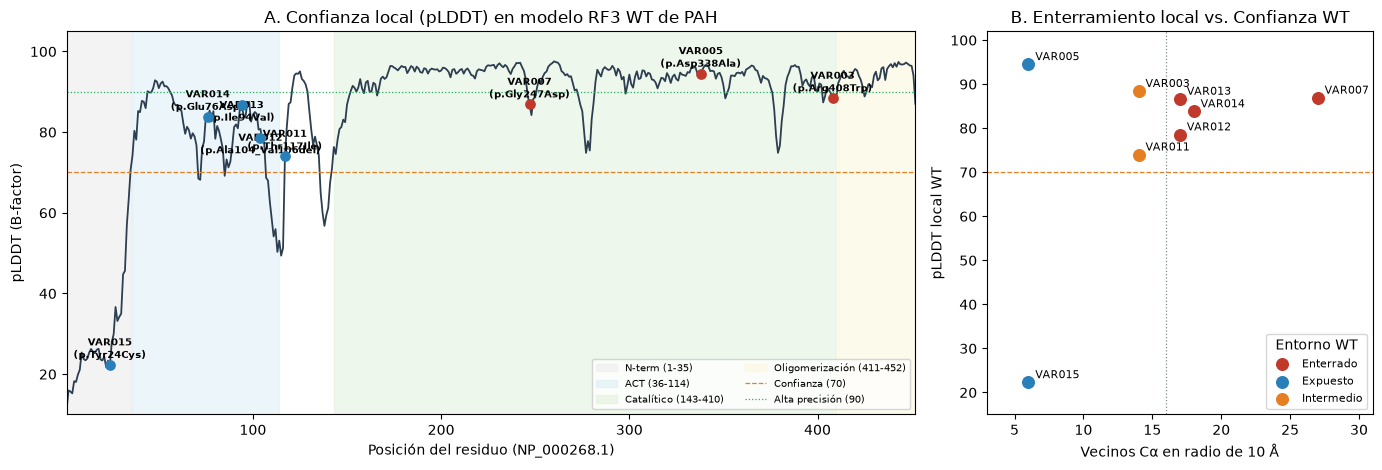

Resumen estructural guardado en resultados/rf3/estructura_resumen.tsv


In [8]:
os.makedirs("resultados/figuras", exist_ok=True)
os.makedirs("resultados/rf3", exist_ok=True)

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [2.2, 1]}
)

# Panel A: Perfil de pLDDT por residuo en PAH WT
ax1.axvspan(1, 35, color="#f0f0f0", alpha=0.8, label="N-term (1-35)")
ax1.axvspan(36, 114, color="#d9edf7", alpha=0.5, label="ACT (36-114)")
ax1.axvspan(143, 410, color="#dff0d8", alpha=0.5, label="Catalítico (143-410)")
ax1.axvspan(
    411, 452, color="#fcf8e3", alpha=0.7, label="Oligomerización (411-452)"
)
ax1.plot(ca_wt["seq_id"], ca_wt["plddt"], color="#2c3e50", linewidth=1.3)
ax1.axhline(
    70, color="#e67e22", linestyle="--", linewidth=0.9, label="Confianza (70)"
)
ax1.axhline(
    90,
    color="#27ae60",
    linestyle=":",
    linewidth=0.9,
    label="Alta precisión (90)",
)

pos_map = {v[0]: v[2][0] for v in variantes_eval}
for _, row in df_entorno.iterrows():
  res_num = pos_map[row["ID"]]
  color_pt = (
      "#c0392b" if row["ID"] in ("VAR007", "VAR003", "VAR005") else "#2980b9"
  )
  ax1.scatter(res_num, row["pLDDT_local_WT"], color=color_pt, zorder=5, s=45)
  offset_y = 5 if row["ID"] not in ("VAR012", "VAR013") else -11
  ax1.annotate(
      f"{row['ID']}\n({row['protein_change']})",
      (res_num, row["pLDDT_local_WT"]),
      textcoords="offset points",
      xytext=(0, offset_y),
      ha="center",
      fontsize=7.5,
      fontweight="bold",
  )

ax1.set_title("A. Confianza local (pLDDT) en modelo RF3 WT de PAH")
ax1.set_xlabel("Posición del residuo (NP_000268.1)")
ax1.set_ylabel("pLDDT (B-factor)")
ax1.set_xlim(1, 452)
ax1.set_ylim(10, 105)
ax1.legend(loc="lower right", fontsize=7.5, ncol=2)

# Panel B: Enterramiento local (Cα en 10 Å) vs pLDDT local
colores_exp = {
    "Enterrado": "#c0392b",
    "Intermedio": "#e67e22",
    "Expuesto": "#2980b9",
}
for exp_tipo, grupo in df_entorno.groupby("exposicion_WT"):
  ax2.scatter(
      grupo["empaquetamiento_CA_10A"],
      grupo["pLDDT_local_WT"],
      color=colores_exp[exp_tipo],
      s=70,
      label=exp_tipo,
      zorder=4,
  )
for _, r in df_entorno.iterrows():
  ax2.annotate(
      r["ID"],
      (r["empaquetamiento_CA_10A"], r["pLDDT_local_WT"]),
      textcoords="offset points",
      xytext=(5, 3),
      fontsize=8,
  )

ax2.axhline(70, color="#e67e22", linestyle="--", linewidth=0.9)
ax2.axvline(16, color="#7f8c8d", linestyle=":", linewidth=0.9)
ax2.set_title("B. Enterramiento local vs. Confianza WT")
ax2.set_xlabel("Vecinos Cα en radio de 10 Å")
ax2.set_ylabel("pLDDT local WT")
ax2.set_xlim(3, 31)
ax2.set_ylim(15, 102)
ax2.legend(title="Entorno WT", fontsize=8)

plt.tight_layout()
plt.savefig("resultados/figuras/05_estructura_plddt_entorno.png", dpi=200)
plt.show()

# Guardar tabla resumen en la ruta que lee 06_integracion.ipynb (y copia en resultados/)
resumen_export = df_entorno[[
    "ID",
    "pLDDT_local_WT",
    "exposicion_WT",
    "empaquetamiento_CA_10A",
    "contactos_polares_3_5A",
    "RMSD_vs_WT",
    "evaluacion_estructural",
]].copy()

resumen_export.to_csv("resultados/rf3/estructura_resumen.tsv", sep="\t", index=False)
resumen_export.to_csv("resultados/estructura_resumen.tsv", sep="\t", index=False)
print("Resumen estructural guardado en resultados/rf3/estructura_resumen.tsv")

## Cierre de la sección

- **Observamos:** El modelo RF3 WT extraído de `neurosnap-session.json` presenta alta confianza en el dominio catalítico (pLDDT medio 92,88) y de oligomerización (94,35), pero baja confianza en el extremo N-terminal (28,68). En la estructura WT, `Gly247` (`VAR007`, pLDDT 86,90) es el sitio más enterrado del panel (27 vecinos $C\alpha$ en 10 Å, 0 contactos polares), `Arg408` (`VAR003`, pLDDT 88,41) mantiene 4 contactos polares de anclaje (`Leu308`, `Leu311`, `Ile406`, `Phe410`), y `Asp338` (`VAR005`, pLDDT 94,52) está expuesto en superficie (6 vecinos $C\alpha$). Para `VAR007`, la tabla de RF3 confirma que el plegamiento global se conserva (`pTM = 0,80`, `pLDDT = 87,0 %`, `Has Clash = False`).
- **Inferimos que:** `VAR007` (`p.Gly247Asp`) desestabiliza localmente el dominio catalítico al introducir una cadena lateral voluminosa y con carga negativa en un bolsillo hidrofóbico densamente empaquetado sin contra-cargas, mientras que `VAR003` (`p.Arg408Trp`) rompe los puentes de hidrógeno que fijan la bisagra hacia el dominio de oligomerización. En cambio, `VAR015` (`p.Tyr24Cys`, pLDDT 22,30) cae en una cola desordenada sin soporte estructural confiable.
- **La evidencia aporta:** Confianza local por residuo (pLDDT), grado de enterramiento ($C\alpha$ en 10 Å), inventario de vecinos a 5 Å y contactos polares nativos a 3,5 Å para las 8 variantes que alteran la proteína, más métricas globales RF3 de `VAR007`.
- **Concluimos:** La capa estructural respalda la priorización de `VAR007` (`p.Gly247Asp`) y `VAR003` (`p.Arg408Trp`) en el dominio catalítico, seguidas por `VAR005` (`p.Asp338Ala`).
- **Falta evidencia:** Coordenadas 3D (`.cif`/`.pdb`) de los mutantes para medir RMSD atómico directo, modelado del homotetrámero nativo con $\text{Fe}^{2+}$ y $\text{BH}_4$, alineamiento local con el cristal PDB `6HYC` y ensayos experimentales de actividad o termoestabilidad.